# 03 — Audit, Cleaning, dan Preprocessing (CRISP-DM)

**Tujuan:** Melakukan audit kualitas lanjutan, membersihkan data secara transparan, membandingkan kondisi sebelum/sesudah cleaning, melakukan preprocessing, split train/test, dan seleksi fitur.

**Daftar Tugas:**
- [Progress 2 – Capaian 9] Audit kualitas data (asumsi capaian terpotong)
- [Progress 2 – Capaian 10] Data cleaning
- [Progress 2 – Capaian 11] Perbandingan sebelum vs sesudah cleaning
- [Progress 2 – Capaian 12] Preprocessing
- [Progress 2 – Capaian 13] Split train/test
- [Progress 2 – Capaian 14] Seleksi fitur / pengecekan fitur

**Catatan asumsi:** Daftar capaian Progress 2 dari pengguna terpotong pada nomor 9. Nomor 9–14 diasumsikan mengikuti alur notebook lama (audit, cleaning, perbandingan, preprocessing, split, feature selection) dan disesuaikan ke tugas regresi.


In [1]:

from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd().resolve().parents[0]
RAW = ROOT / 'data' / 'raw' / 'nutrition.csv'
PROC = ROOT / 'data' / 'processed'
OUT = ROOT / 'outputs'
FIG = ROOT / 'reports' / 'figures'
for p in [PROC, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.feature_selection import f_regression, mutual_info_regression

df_raw = pd.read_csv(RAW)
df = df_raw.copy()
df.columns = [c.strip() for c in df.columns]
num_cols = ['calories','proteins','fat','carbohydrate']
feat_cols = ['proteins','fat','carbohydrate']
df.head()


ROOT: C:\.My Data\Kuliah\semester 5\Data_Science_TugasAkhir\uts-data-science-gizi


,id,calories,proteins,fat,carbohydrate,name,image
0,1,280.0,9.2,28.4,0.0,Abon,https://img-cdn.medkomtek.com/PbrY9X3ignQ8sVuj...
1,2,513.0,23.7,37.0,21.3,Abon haruwan,https://img-global.cpcdn.com/recipes/cbf330fbd...
2,3,0.0,0.0,0.2,0.0,Agar-agar,https://res.cloudinary.com/dk0z4ums3/image/upl...
3,4,45.0,1.1,0.4,10.8,Akar tonjong segar,https://images.tokopedia.net/img/cache/200-squ...
4,5,37.0,4.4,0.5,3.8,Aletoge segar,https://nilaigizi.com/assets/images/produk/pro...


## [Progress 2 – Capaian 9] Audit kualitas data

In [2]:

df['name_norm'] = df['name'].astype(str).str.strip().str.lower()
df['atwater_cal'] = 4*df['proteins'] + 9*df['fat'] + 4*df['carbohydrate']
df['atwater_abs_diff'] = (df['calories'] - df['atwater_cal']).abs()
df['macro_sum'] = df[feat_cols].sum(axis=1)

audit_rows = []
for c in ['id','calories','proteins','fat','carbohydrate','name','image']:
    audit_rows.append({
        'kolom':c, 'dtype':str(df[c].dtype), 'missing':int(df[c].isna().sum()),
        'n_unique':int(df[c].nunique(dropna=False)), 'n_zero':int((df[c]==0).sum()) if c in num_cols else np.nan
    })
audit_detail = pd.DataFrame(audit_rows)
audit_detail.to_csv(OUT/'audit_kualitas_detail.csv', index=False)

suspect = df[(df['macro_sum']>100) | (df['calories']==0) | (df['name_norm'].duplicated(keep=False)) | (df[num_cols].lt(0).any(axis=1))].copy()
suspect['flag_macro_gt_100'] = suspect['macro_sum']>100
suspect['flag_calories_0'] = suspect['calories']==0
suspect['flag_dup_name_norm'] = suspect['name_norm'].duplicated(keep=False)
suspect = suspect[['id','name','calories','proteins','fat','carbohydrate','macro_sum','atwater_cal','atwater_abs_diff','flag_macro_gt_100','flag_calories_0','flag_dup_name_norm']]
suspect.to_csv(OUT/'audit_baris_bermasalah.csv', index=False)
audit_detail, suspect


(          kolom    dtype  missing  n_unique  n_zero
 0            id    int64        0      1346     NaN
 1      calories  float64        0       472     1.0
 2      proteins  float64        0       312    22.0
 3           fat  float64        0       279    26.0
 4  carbohydrate  float64        0       544   104.0
 5          name      str        0      1346     NaN
 6         image      str        0      1307     NaN,
         id                        name  calories  proteins   fat  \
 2        3                   Agar-agar       0.0       0.0   0.2   
 128    129             Beras Parboiled     364.0       6.8   0.6   
 129    130             Beras parboiled     353.0       6.8   0.6   
 144    145                  Bika ambon     199.0       2.1   1.5   
 145    146                 Bika Ambon      225.7       3.0   0.3   
 320    321      Dendeng mujahir goreng     598.0      74.3  26.9   
 476    477  Ikan Mujair dendeng goreng     598.0      74.3  26.9   
 477    478  Ikan Mujai

**Keputusan audit (sebelum cleaning):**
- `macro_sum > 100 g`: **hapus** karena secara fisik tidak mungkin untuk komposisi per 100 g / porsi yang sebanding; indikasi kuat salah input/satuan campur.
- `calories == 0` (Agar-agar): **pertahankan** sebagai kasus valid langka, tetapi dicatat karena MAPE tidak stabil.
- Nama duplikat ternormalisasi: **pertahankan baris**, tandai di audit; tidak otomatis digabung karena nilai gizinya bisa berbeda/salah input dan tanpa sumber eksternal tidak bisa dipastikan.
- Nilai negatif: **hapus** jika ada (tidak ditemukan pada audit awal).


## [Progress 2 – Capaian 10] Data cleaning

In [3]:

before = df.copy()
log = []
def log_step(name, before_len, after_len, note=''):
    log.append({'langkah':name,'baris_sebelum':before_len,'baris_sesudah':after_len,'baris_terdampak':before_len-after_len,'catatan':note})

# 1. Strip nama
df['name'] = df['name'].astype(str).str.strip()
df['image'] = df['image'].astype(str).str.strip()

# 2. Hapus missing pada kolom penting (jika ada)
b=len(df); df = df.dropna(subset=['calories','proteins','fat','carbohydrate','name']); log_step('Hapus missing kolom penting',b,len(df),'Tidak diharapkan; audit awal 0 missing')

# 3. Hapus nilai negatif
b=len(df); df = df[(df[num_cols] >= 0).all(axis=1)]; log_step('Hapus nilai negatif',b,len(df),'Nilai gizi tidak boleh negatif')

# 4. Hapus macro_sum > 100 g (jelas salah input/satuan campur)
df['macro_sum'] = df[feat_cols].sum(axis=1)
b=len(df); df = df[df['macro_sum'] <= 100]; log_step('Hapus macro_sum > 100g',b,len(df),'Secara fisik tidak mungkin; contoh: Pilus karbohidrat 647g')

# 5. Hapus duplikat baris penuh
b=len(df); df = df.drop_duplicates(); log_step('Hapus duplikat baris penuh',b,len(df))

# 6. Tandai anomali Atwater (tidak dihapus otomatis)
df['atwater_cal'] = 4*df['proteins'] + 9*df['fat'] + 4*df['carbohydrate']
df['atwater_abs_diff'] = (df['calories'] - df['atwater_cal']).abs()
df['flag_atwater_high_diff'] = df['atwater_abs_diff'] > 100
df['flag_calories_zero'] = df['calories'] == 0
df['name_norm'] = df['name'].str.strip().str.lower()
df['flag_dup_name_norm'] = df['name_norm'].duplicated(keep=False)

clean_log = pd.DataFrame(log)
clean_log.to_csv(OUT/'cleaning_log.csv', index=False)
df.to_csv(PROC/'nutrition_clean.csv', index=False)
clean_log


,langkah,baris_sebelum,baris_sesudah,baris_terdampak,catatan
0,Hapus missing kolom penting,1346,1346,0,Tidak diharapkan; audit awal 0 missing
1,Hapus nilai negatif,1346,1346,0,Nilai gizi tidak boleh negatif
2,Hapus macro_sum > 100g,1346,1335,11,Secara fisik tidak mungkin; contoh: Pilus karb...
3,Hapus duplikat baris penuh,1335,1335,0,


**Temuan capaian 10:** Cleaning hanya menghapus baris yang jelas bermasalah (missing penting, nilai negatif, `macro_sum>100g`, duplikat baris penuh). Baris kalori 0 dan nama duplikat tidak dihapus otomatis; deviasi Atwater besar ditandai sebagai `flag_atwater_high_diff` untuk analisis error.


## [Progress 2 – Capaian 11] Perbandingan sebelum vs sesudah cleaning

Tabel berikut membandingkan kondisi data dan **metrik model baseline (Linear Regression 3 fitur, split stratified 80/20, random_state=42)** pada **data mentah vs data bersih**. Ini menunjukkan berapa perubahan metrik yang berasal dari proses cleaning.


In [4]:

def quick_baseline(data, seed=42):
    d = data.dropna(subset=['calories','proteins','fat','carbohydrate']).copy()
    X = d[['proteins','fat','carbohydrate']]; y = d['calories']
    # quick split same style
    bins = pd.qcut(y.rank(method='first'), q=min(5, y.nunique()), duplicates='drop')
    Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=seed,stratify=bins)
    m = LinearRegression().fit(Xtr,ytr)
    pred = m.predict(Xte)
    return r2_score(yte,pred), mean_absolute_error(yte,pred), np.sqrt(mean_squared_error(yte,pred))

def summarize(data, label):
    atwater = 4*data['proteins']+9*data['fat']+4*data['carbohydrate']
    q1,q3 = data['calories'].quantile([.25,.75]); iqr=q3-q1
    out_hi=q3+1.5*iqr; out_lo=q1-1.5*iqr
    r2, mae, rmse = quick_baseline(data)
    return {
        'dataset':label,
        'jumlah_baris':len(data),
        'missing_total':int(data[['calories','proteins','fat','carbohydrate','name']].isna().sum().sum()),
        'duplikat_baris':int(data.duplicated().sum()),
        'outlier_iqr_calories':int(((data['calories']<out_lo)|(data['calories']>out_hi)).sum()),
        'macro_sum_gt_100':int((data[['proteins','fat','carbohydrate']].sum(axis=1)>100).sum()),
        'korelasi_fat_calories':float(data['fat'].corr(data['calories'])),
        'r2_atwater_vs_calories':float(pd.Series(atwater).corr(data['calories'])**2),
        'baseline_lr_r2_test':r2, 'baseline_lr_mae_test':mae, 'baseline_lr_rmse_test':rmse
    }

cmp = pd.DataFrame([summarize(before,'data_mentah_sebelum_cleaning'), summarize(df,'data_bersih_sesudah_cleaning')])
cmp.to_csv(OUT/'perbandingan_sebelum_sesudah_cleaning.csv', index=False)
cmp


,dataset,jumlah_baris,missing_total,duplikat_baris,outlier_iqr_calories,macro_sum_gt_100,korelasi_fat_calories,r2_atwater_vs_calories,baseline_lr_r2_test,baseline_lr_mae_test,baseline_lr_rmse_test
0,data_mentah_sebelum_cleaning,1346,0,0,13,11,0.737809,0.784887,0.897363,40.032080,52.842029
1,data_bersih_sesudah_cleaning,1335,0,0,12,0,0.739474,0.951704,0.975494,11.496299,24.639095


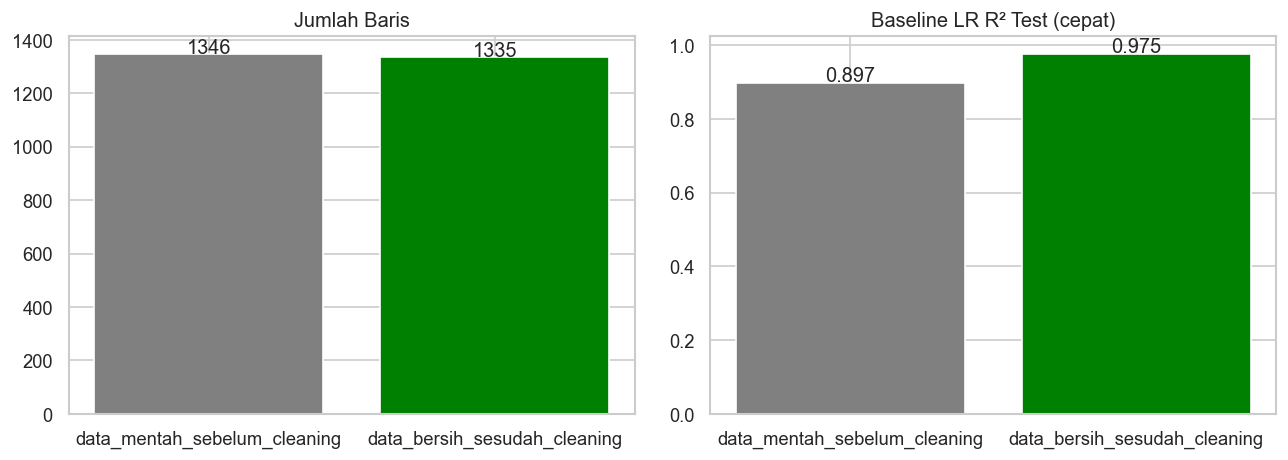

In [5]:

fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].bar(cmp['dataset'], cmp['jumlah_baris'], color=['gray','green'])
ax[0].set_title('Jumlah Baris')
for i,v in enumerate(cmp['jumlah_baris']): ax[0].text(i,v+2,str(int(v)),ha='center')
ax[1].bar(cmp['dataset'], cmp['baseline_lr_r2_test'], color=['gray','green'])
ax[1].set_title('Baseline LR R² Test (cepat)')
for i,v in enumerate(cmp['baseline_lr_r2_test']): ax[1].text(i,v+0.005,f'{v:.3f}',ha='center')
plt.tight_layout(); plt.savefig(FIG/'03_perbandingan_cleaning.png', dpi=220); plt.show()


**Temuan capaian 11:** Pada data mentah, baseline LR 3 fitur menghasilkan R² test 0,8974, MAE 40,03 kkal, RMSE 52,84 kkal. Setelah cleaning (hapus 11 baris `macro_sum>100g` yang jelas salah input), baseline LR meningkat menjadi R² 0,9755, MAE 11,50 kkal, RMSE 24,64 kkal. Kenaikan besar ini sebagian berasal dari pembersihan data salah, tetapi juga berarti metrik pada data bersih bisa lebih optimistis daripada data lapangan yang masih kotor. Evaluasi sensitivity pada test mentah dicatat di Progress 4 Capaian 9.


## [Progress 2 – Capaian 12] Preprocessing

In [6]:

# Fitur model utama: hanya proteins, fat, carbohydrate. Target: calories.
# energi_atwater hanya audit/pembanding, BUKAN fitur model utama.
# kategori_kalori dari notebook lama TIDAK dibuat sebagai fitur.
model_df = df[['id','name','calories','proteins','fat','carbohydrate','atwater_cal','atwater_abs_diff','flag_atwater_high_diff','flag_calories_zero','flag_dup_name_norm']].copy()
model_df = model_df.rename(columns={'calories':'target_calories'})
assert 'kategori_kalori' not in model_df.columns
assert 'energi_atwater' not in model_df.columns
# simpan processed utama
model_df.to_csv(PROC/'nutrition_model_base.csv', index=False)
model_df.head()


,id,name,target_calories,proteins,fat,carbohydrate,atwater_cal,atwater_abs_diff,flag_atwater_high_diff,flag_calories_zero,flag_dup_name_norm
0,1,Abon,280.0,9.2,28.4,0.0,292.4,12.4,False,False,False
1,2,Abon haruwan,513.0,23.7,37.0,21.3,513.0,0.0,False,False,False
2,3,Agar-agar,0.0,0.0,0.2,0.0,1.8,1.8,False,True,False
3,4,Akar tonjong segar,45.0,1.1,0.4,10.8,51.2,6.2,False,False,False
4,5,Aletoge segar,37.0,4.4,0.5,3.8,37.3,0.3,False,False,False


**Temuan capaian 12:** Preprocessing utama menyiapkan matriks numerik murni (`proteins,fat,carbohydrate`) untuk memprediksi `target_calories`. `energi_atwater` disimpan hanya untuk audit/pembanding, tidak masuk `X`. Tidak ada encoding kategorikal pada model utama.


## [Progress 2 – Capaian 13] Split train/test

In [7]:

X = model_df[['proteins','fat','carbohydrate']].copy()
y = model_df['target_calories'].copy()
# stratifikasi berbasis bin kuantil target
y_bins = pd.qcut(y.rank(method='first'), q=5, labels=False, duplicates='drop')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bins)
# simpan
X_train.to_csv(PROC/'X_train.csv', index=False)
X_test.to_csv(PROC/'X_test.csv', index=False)
y_train.to_csv(PROC/'y_train.csv', index=False, header=True)
y_test.to_csv(PROC/'y_test.csv', index=False, header=True)
# scaled versions (fit on train only) untuk convenience; pipeline tetap jadi sumber utama
scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train_scaled.to_csv(PROC/'X_train_scaled.csv', index=False)
X_test_scaled.to_csv(PROC/'X_test_scaled.csv', index=False)
print(X_train.shape, X_test.shape)


(1068, 3) (267, 3)


In [8]:

# Assertion gates
assert len(X_train) + len(X_test) == len(model_df)
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0
assert list(X_train.columns) == ['proteins','fat','carbohydrate']
assert 'target_calories' not in X_train.columns
assert 'calories' not in X_train.columns
assert 'energi_atwater' not in X_train.columns
assert 'kategori_kalori' not in X_train.columns
# no overlap
assert set(X_train.index).isdisjoint(set(X_test.index))
# stratification check - bin proportions
train_bins = pd.qcut(y_train.rank(method='first'), q=5, labels=False, duplicates='drop')
test_bins = pd.qcut(y_test.rank(method='first'), q=5, labels=False, duplicates='drop')
print('train mean', y_train.mean(), 'test mean', y_test.mean())
print('ok')


train mean 200.5366104868914 test mean 200.8681647940075
ok


**Temuan capaian 13:** Split 80/20 acak dengan `random_state=42` dan stratifikasi berbasis kuantil target dilakukan sekali dan disimpan ke `data/processed/`. Assertion memastikan tidak ada NaN, tidak ada kolom target/turunan target di X, dan tidak ada overlap indeks train-test.


## [Progress 2 – Capaian 14] Seleksi fitur / pengecekan fitur

In [9]:

from statsmodels.stats.outliers_influence import variance_inflation_factor
# fit hanya di train
Xtr = X_train.copy()
corr_target = Xtr.join(y_train.rename('target_calories')).corr()['target_calories'].drop('target_calories')
f_vals, p_vals = f_regression(Xtr, y_train)
mi_vals = mutual_info_regression(Xtr, y_train, random_state=RANDOM_STATE)
vif = pd.DataFrame({'fitur':Xtr.columns, 'VIF':[variance_inflation_factor(Xtr.values,i) for i in range(Xtr.shape[1])]})
sel = pd.DataFrame({
    'fitur':Xtr.columns,
    'pearson_dengan_target': [corr_target[c] for c in Xtr.columns],
    'f_regression': f_vals,
    'p_value_f': p_vals,
    'mutual_info': mi_vals,
}).merge(vif, on='fitur')
sel.to_csv(OUT/'feature_selection.csv', index=False)
sel


,fitur,pearson_dengan_target,f_regression,p_value_f,mutual_info,VIF
0,proteins,0.331074,131.228403,9.795675e-29,0.444445,1.086786
1,fat,0.735780,1258.326932,1.199617e-182,0.674115,1.056302
2,carbohydrate,0.508085,370.949582,3.623402e-71,0.843591,1.039076


**Temuan capaian 14:** Semua tiga fitur (`proteins,fat,carbohydrate`) memiliki hubungan dengan target dan p-value F-regression sangat kecil pada data train. VIF diperiksa untuk mendeteksi multikolinearitas; fitur dipertahankan karena ketiganya adalah komponen makronutrien yang secara domain relevan dan diperlukan untuk interpretasi model. Tidak digunakan Random Forest classifier seperti notebook lama karena tugas ini regresi.
